# Transient stability prediction for the IEEE 39-bus system with an SVM

**Goal.** Given the voltage and frequency measured at the 10 generator buses (B30-B39) after a disturbance,
predict whether the system stays **stable** or becomes **unstable**.

| | |
|---|---|
| **Inputs (80)** | for each of the 10 generators: 4 voltage-magnitude samples (p.u.) + 4 frequency samples (Hz) |
| **Label** | `Overall_Stability` from the TSI value: **1 = stable, 0 = unstable** |
| **Contingencies** | generator trip, line trip, ground fault + line trip (SLG / LLG / 3PHG), load disconnection |
| **Scenarios** | each contingency simulated at 5 load levels (-4 %, -2 %, 0 %, +2 %, +4 %) and, for faults, 3 fault durations |
| **Model** | RBF-kernel Support Vector Machine (scikit-learn) |

**First try:** all 3,715 cases are used and **no outliers are removed** - the impossible readings caused by the
fluctuations stay in the data.

**Workflow:** load → explore → split into train / validation / test → choose SVM settings → check on validation →
final test → feature importance → save model and predict new cases.

The code lives in the `stability_svm` package next to this notebook; `train_model.py` runs the same steps from the
command line and `predict.py` predicts new cases.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from stability_svm import data, model, evaluate, plots
from stability_svm.config import FEATURES, LABEL, GROUP, STABLE, UNSTABLE, MODEL_FILE, FIGURE_DIR

plots.apply_style()
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)

def show(fig, name):
    """Display a figure and keep a PNG copy in figures/."""
    plots.save(fig, name)
    plt.show()

## 1. Load the data

In [2]:
raw = data.load_dataset()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns  ({len(FEATURES)} measurement columns)")
display(raw.head())

3,715 rows x 85 columns  (80 measurement columns)


,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,B30_Vmag_1,B30_Vmag_2,B30_Vmag_3,B30_Vmag_4,B31_Vmag_1,B31_Vmag_2,B31_Vmag_3,B31_Vmag_4,B32_Vmag_1,B32_Vmag_2,B32_Vmag_3,...,B36_FreqHz_3,B36_FreqHz_4,B37_FreqHz_1,B37_FreqHz_2,B37_FreqHz_3,B37_FreqHz_4,B38_FreqHz_1,B38_FreqHz_2,B38_FreqHz_3,B38_FreqHz_4,B39_FreqHz_1,B39_FreqHz_2,B39_FreqHz_3,B39_FreqHz_4,Overall_Stability
0,GT_00001,-4%,Generator_Trip,GenTrip_Bus30,0.9538,0.9532,0.9528,0.9524,0.8109,0.8102,0.8097,0.8093,0.9810,0.9802,0.9796,...,49.9997,49.9978,49.9942,49.9829,49.9770,49.9728,49.9991,49.9970,49.9955,49.9940,49.9994,49.9983,49.9978,49.9974,1
1,GT_00002,-4%,Generator_Trip,GenTrip_Bus31,1.0003,0.9978,0.9961,0.9948,0.6737,0.6710,0.6690,0.6674,0.9668,0.9614,0.9572,...,50.0024,49.9976,49.9985,49.9940,49.9897,49.9852,49.9994,49.9979,49.9968,49.9955,49.9987,49.9963,49.9951,49.9941,1
2,GT_00003,-4%,Generator_Trip,GenTrip_Bus32,0.9982,0.9951,0.9930,0.9916,0.7619,0.7581,0.7555,0.7537,0.8081,0.8050,0.8027,...,49.9988,49.9920,49.9972,49.9899,49.9836,49.9774,49.9990,49.9965,49.9946,49.9926,49.9985,49.9956,49.9942,49.9932,1
3,GT_00004,-4%,Generator_Trip,GenTrip_Bus33,1.0037,1.0020,1.0007,0.9998,0.8082,0.8063,0.8048,0.8036,0.9805,0.9790,0.9777,...,49.9746,49.9665,49.9967,49.9887,49.9829,49.9771,49.9988,49.9952,49.9923,49.9893,49.9997,49.9987,49.9980,49.9973,1
4,GT_00005,-4%,Generator_Trip,GenTrip_Bus34,1.0054,1.0047,1.0042,1.0037,0.8124,0.8118,0.8110,0.8102,0.9817,0.9813,0.9808,...,49.9827,49.9783,49.9984,49.9938,49.9903,49.9867,49.9994,49.9975,49.9958,49.9941,49.9998,49.9993,49.9989,49.9985,1


In [3]:
display(data.quality_report(raw).to_frame())

,count
rows,3715
columns,85
missing values,0
infinite values,0
duplicate rows,0
rows with voltage > 1.1 p.u.,10
rows with |f - 50| > 5 Hz,10
rows with an impossible reading,10


No missing values or duplicates. **10 rows contain physically impossible readings** (voltages up to 13 p.u.,
frequencies between 24 and 81 Hz). As agreed for this first try they are **kept**.

Next, readable scenario columns are parsed from `Contingency_ID` (fault kind, fault duration) and
`Operating_Condition` (load change). They are used only for analysis - the model sees just the 80 measurements.

In [4]:
df = data.add_scenario_details(raw)
display(df[["Case_ID", "Operating_Condition", "Contingency_Type", "Contingency_ID",
            "Fault_Kind", "Fault_Time_s", "Load_Change_pct", LABEL]].sample(6, random_state=1))
print(f"{df[GROUP].nunique()} distinct contingencies, each at {df.groupby(GROUP).size().unique()} load levels")

,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,Fault_Kind,Fault_Time_s,Load_Change_pct,Overall_Stability
3547,GF_03548,+4%,Ground_Fault_Line_Trip,SLG_Line17_18_Ckt1_Loc20pct_Fault0p5s,SLG,0.5,4.0,1
3017,GF_03018,+2%,Ground_Fault_Line_Trip,3PHG_Line25_26_Ckt1_Loc20pct_Fault0p1s,3PHG,0.1,2.0,1
3304,GF_03305,+4%,Ground_Fault_Line_Trip,LLG_Line6_11_Ckt1_Loc80pct_Fault0p1s,LLG,0.1,4.0,1
1773,GF_01774,-2%,Ground_Fault_Line_Trip,LLG_Line23_24_Ckt1_Loc20pct_Fault0p1s,LLG,0.1,-2.0,1
1794,GF_01795,-2%,Ground_Fault_Line_Trip,3PHG_Line25_26_Ckt1_Loc80pct_Fault0p1s,3PHG,0.1,-2.0,1
99,LD_00100,0%,Load_Disconnection,LoadDisconnect_Bus24_ID1,Load disconnection,NaN,0.0,1


743 distinct contingencies, each at [5] load levels


## 2. Explore the data
### 2.1 Class balance

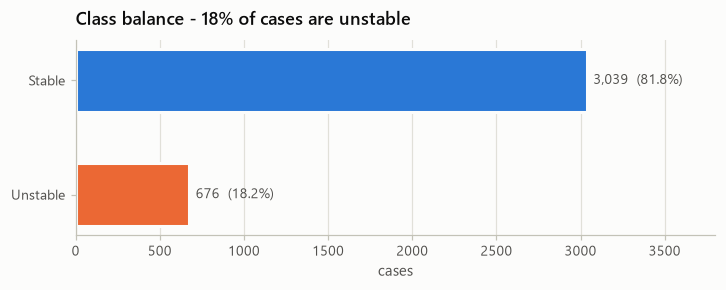

In [5]:
show(plots.plot_class_balance(df), "01_class_balance")

Only about 1 case in 5 is unstable, so plain accuracy would look good even for a model that always says "stable"
(81.8 %). The model therefore uses **class weights**, and results are reported as **balanced accuracy**
(the average of the stable and unstable hit rates) and **unstable recall** (share of unstable cases caught).

### 2.2 What makes a case unstable?

,cases,unstable,unstable_%
Contingency_Type,,,
Generator_Trip,50,5,10.0
Ground_Fault_Line_Trip,3060,458,15.0
Line_Trip,510,213,41.8
Load_Disconnection,95,0,0.0


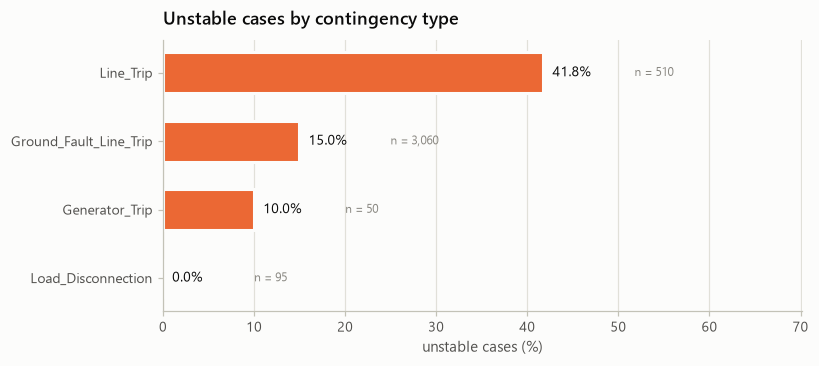

In [6]:
tab = df.groupby("Contingency_Type")[LABEL].agg(cases="size", unstable=lambda s: int((s == UNSTABLE).sum()))
tab["unstable_%"] = (100 * tab["unstable"] / tab["cases"]).round(1)
display(tab)
show(plots.plot_unstable_rate(df, "Contingency_Type", title="Unstable cases by contingency type"),
     "02_unstable_by_contingency_type")

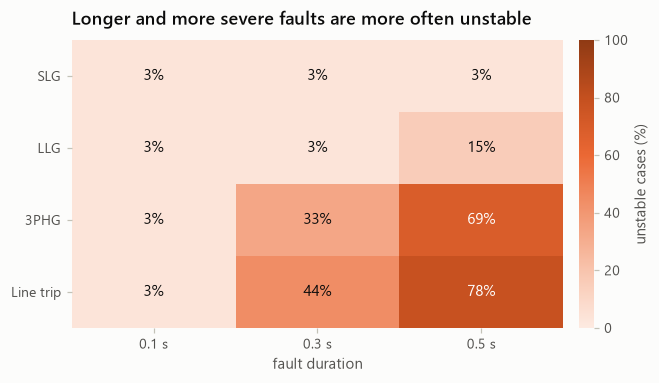

In [7]:
show(plots.plot_fault_time_heatmap(df), "03_unstable_by_fault_and_time")

* **Fault duration** is the strongest driver: with 0.1 s clearing almost every fault is stable; at 0.5 s many are not.
* **Fault type:** three-phase-to-ground (3PHG) faults are far more severe than LLG, which are more severe than SLG.
* The few unstable 0.1 s cases are all on **line 16-19** - tripping it separates buses 19, 20, 33 and 34 (the
  generators at B33 and B34) from the rest of the network, so every contingency on that line is unstable.

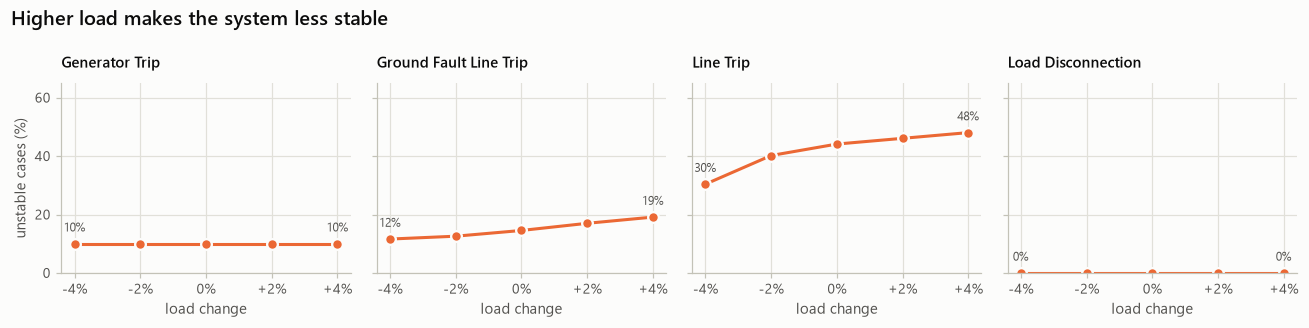

In [8]:
show(plots.plot_rate_vs_load(df), "04_unstable_vs_load")

Higher load makes line trips and ground faults more often unstable. Generator trips (only the Bus 39 unit is unstable)
and load disconnections (always stable) do not change with load.

### 2.3 How do voltage and frequency behave?

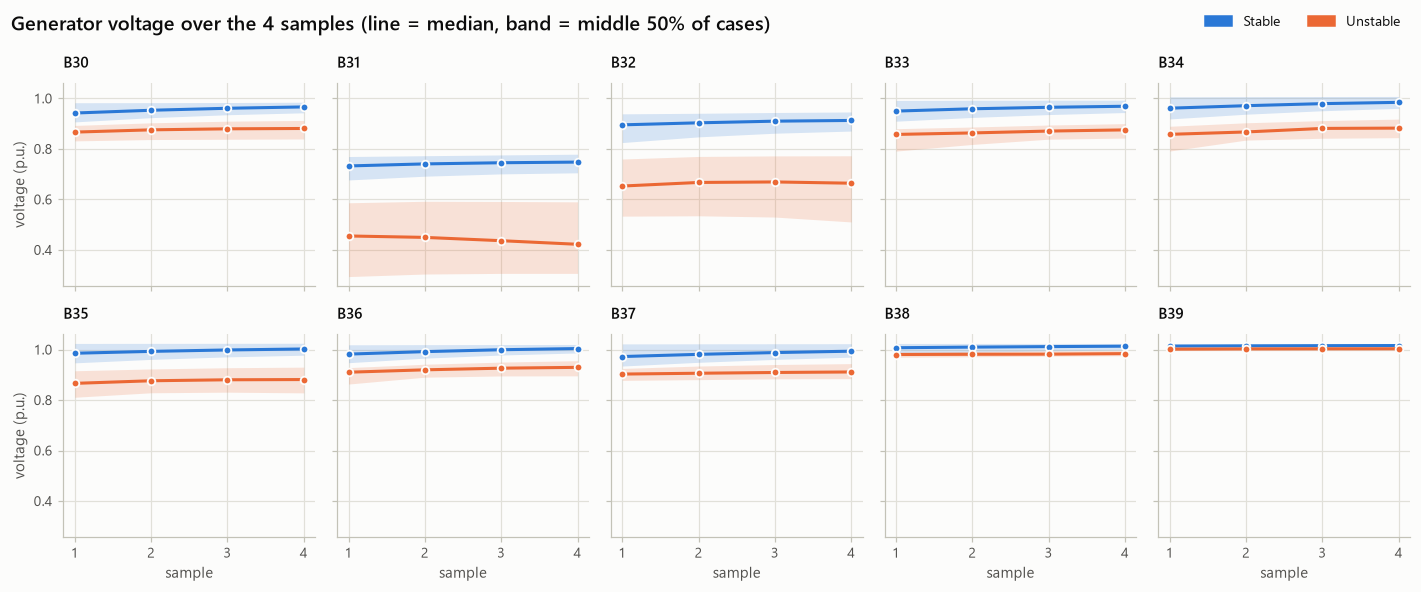

In [9]:
show(plots.plot_sample_traces(df, "voltage"), "05_voltage_traces")

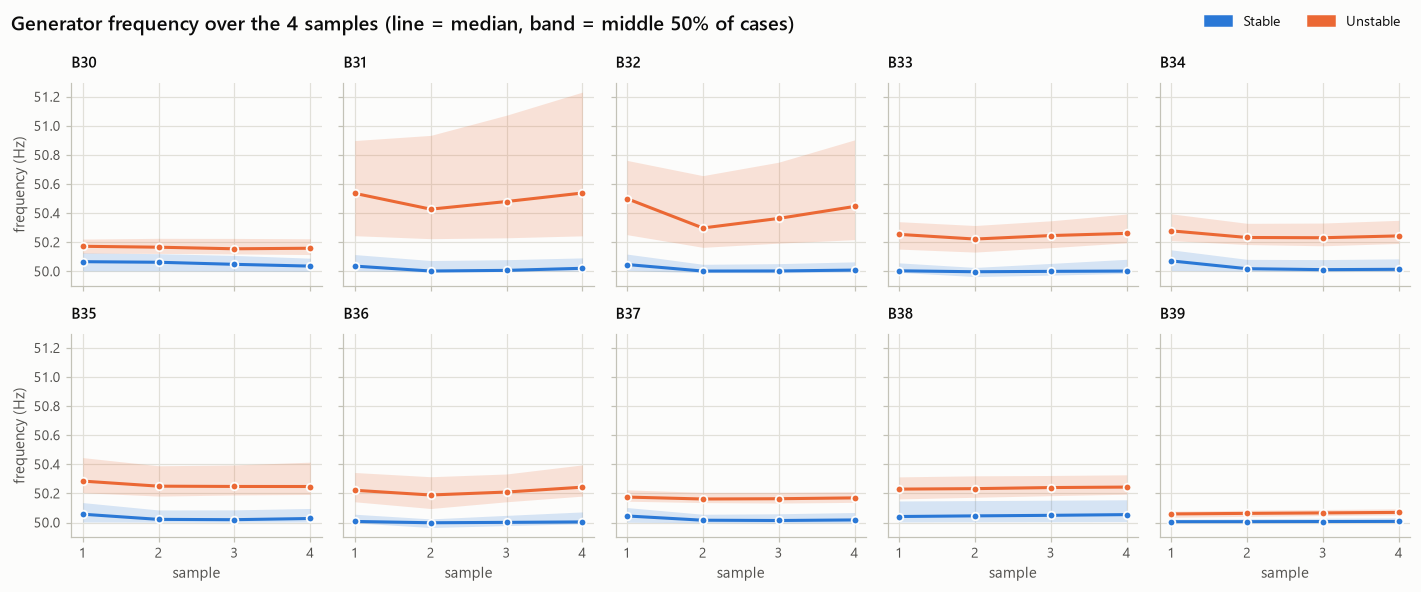

In [10]:
show(plots.plot_sample_traces(df, "frequency"), "06_frequency_traces")

Unstable cases show clearly **lower generator voltages** (largest gaps at B31 and B32) and **higher, more spread-out
frequencies** (again most visible at B31 and B32). B39 differs least between the classes, and B38 differs mainly in
frequency. Note that B31 sits around 0.7-0.8 p.u. even in stable cases.

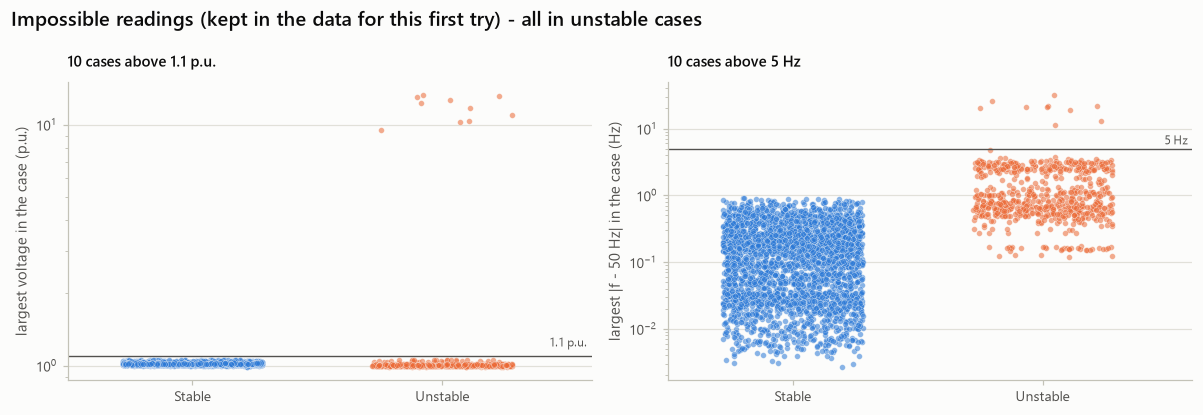

,Case_ID,Operating_Condition,Contingency_ID,Overall_Stability
1044,GF_01045,-4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
1050,GF_01051,-4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
1656,GF_01657,-2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
1662,GF_01663,-2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
2268,GF_02269,0%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
2274,GF_02275,0%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
2880,GF_02881,+2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
2886,GF_02887,+2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
3492,GF_03493,+4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
3498,GF_03499,+4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0


In [11]:
show(plots.plot_extreme_values(df), "07_impossible_readings")
extreme = df[data.extreme_rows(df)]
display(extreme[["Case_ID", "Operating_Condition", "Contingency_ID", LABEL]])

All 10 impossible rows come from 3PHG faults on line 16-19 (0.3 s and 0.5 s, 80 % location) - the islanded
generators lose synchronism and the measurement blows up. They are all labelled unstable and stay in the data.

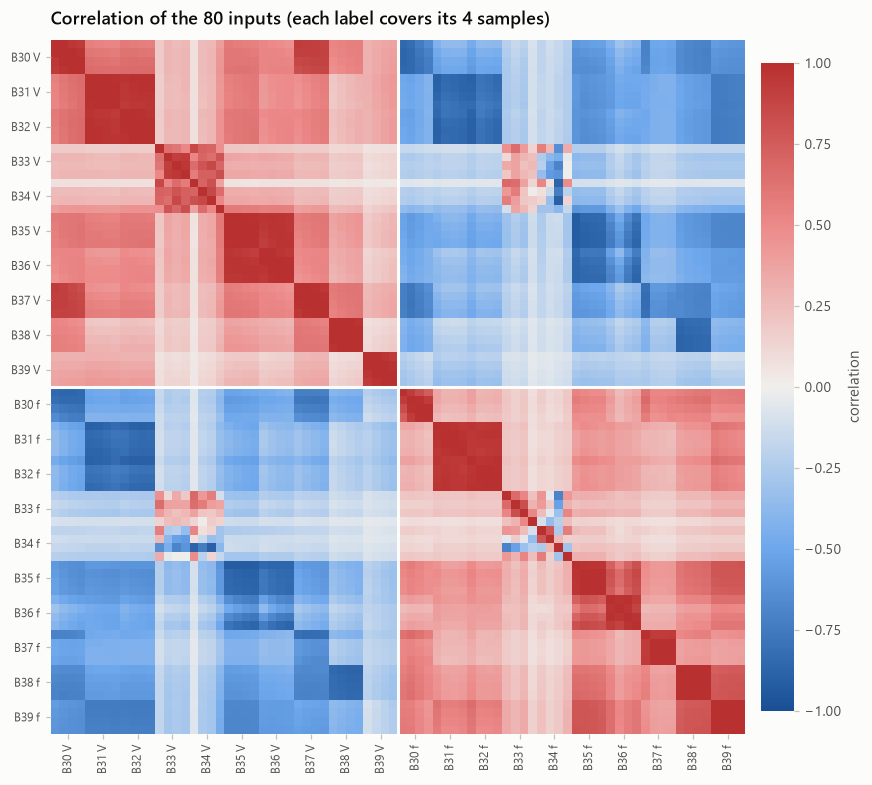

In [12]:
show(plots.plot_correlation(df), "08_correlation")

The 4 samples of the same bus are highly correlated (bright 4x4 blocks along the diagonal), so the 80 inputs carry
much less than 80 independent pieces of information. An RBF SVM handles this redundancy well.

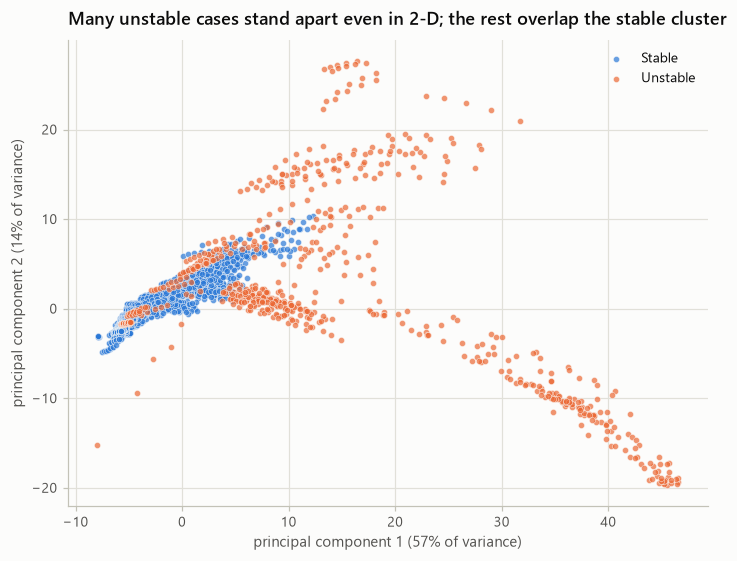

In [13]:
show(plots.plot_pca(df), "09_pca")

Even a flat 2-D projection places many unstable cases away from the stable cluster; the rest overlap it. Separating
those needs all 80 dimensions and a non-linear boundary - the reason for using an RBF-kernel SVM.

## 3. Split into train / validation / test

The split is made **by contingency**: all 5 load levels of one contingency go into the same set. A random row split
would put almost identical cases (same fault, load changed by 2 %) into both training and test, and the test score
would overstate how well the model handles a contingency it has never seen.

Each set keeps about the same share of unstable cases (stratified).

The 2 contingencies that contain the impossible readings are always placed in the **training** set: this first try is
meant to train *with* them, and a later try that removes or caps them can then be compared on exactly the same
validation and test sets.

In [14]:
train, val, test = data.split_train_val_test(df)
summary = data.split_summary(train, val, test)
display(summary)
for a, b, n1, n2 in ((train, val, "train", "validation"), (train, test, "train", "test"), (val, test, "validation", "test")):
    print(f"contingencies shared by {n1} and {n2}: {len(set(a[GROUP]) & set(b[GROUP]))}")
print("rows with impossible readings (train / validation / test):",
      [int(data.extreme_rows(s).sum()) for s in (train, val, test)])

,rows,contingencies,stable,unstable,unstable_pct,share_of_rows_pct
set,,,,,,
Train,2655,531,2172,483,18.2,71.5
Validation,530,106,434,96,18.1,14.3
Test,530,106,433,97,18.3,14.3


contingencies shared by train and validation: 0
contingencies shared by train and test: 0
contingencies shared by validation and test: 0
rows with impossible readings (train / validation / test): [10, 0, 0]


generator-trip contingencies per set: {'train': 8, 'validation': 1, 'test': 1}


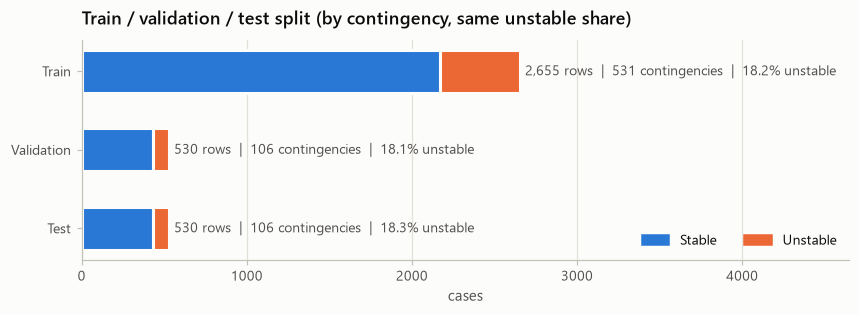

In [15]:
gt = {name: s.loc[s["Contingency_Type"] == "Generator_Trip", GROUP].nunique() for name, s in
      (("train", train), ("validation", val), ("test", test))}
print("generator-trip contingencies per set:", gt)
show(plots.plot_split_composition(summary), "10_split")

## 4. Choose the SVM settings

The model is a pipeline: **scaler → RBF-kernel SVM** with `class_weight="balanced"`.

* **C** - how strongly training mistakes are penalised (large C = tighter fit, risk of overfitting)
* **gamma** - how far the influence of one training case reaches (large gamma = more local, wigglier boundary)
* **scaler** - `standard` (mean / standard deviation) or `robust_clip` (median / interquartile range, then values
  limited to ±20, so the impossible readings cannot dominate). Neither removes any rows.

Every combination is scored by **grouped 5-fold cross-validation inside the training set**: the training
contingencies are split into 5 groups, each group is held out once, and the 5 balanced accuracies are averaged.

,scaler,C,cv_bal_acc,cv_std,gamma_label
0,robust_clip,10.0,0.9743,0.0159,0.001
1,robust_clip,10.0,0.9737,0.0182,0.01
2,robust_clip,1.0,0.9730,0.0156,0.01
3,standard,100.0,0.9715,0.0128,0.001
4,standard,10.0,0.9714,0.0151,0.003
5,robust_clip,10.0,0.9703,0.0144,0.003
6,robust_clip,100.0,0.9675,0.0169,0.001
7,robust_clip,1.0,0.9673,0.0196,scale
8,robust_clip,1000.0,0.9670,0.0305,0.03
9,robust_clip,10.0,0.9660,0.0184,scale


Chosen settings: {'scaler': 'robust_clip', 'C': 10.0, 'gamma': 0.001}


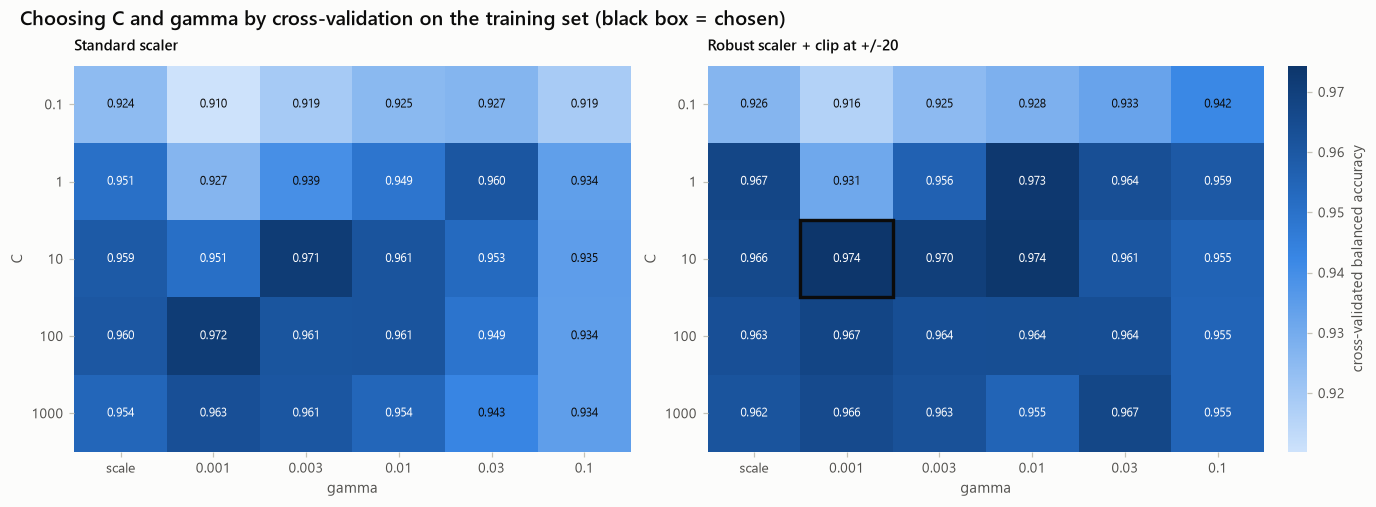

In [16]:
X_tr, y_tr = data.get_xy(train)
X_val, y_val = data.get_xy(val)
X_te, y_te = data.get_xy(test)

cv_results, best = model.tune_with_cv(X_tr, y_tr, train[GROUP])
display(cv_results.drop(columns="gamma").head(10))
print("Chosen settings:", best)
show(plots.plot_grid_heatmaps(cv_results, best), "11_cv_grid")

### Why not choose the settings on the validation set alone?

The validation set has only ~106 contingencies (~20 of them unstable), so a single validation score is noisy.
The cell below scores the same grid on the validation set only and compares its favourite with the
cross-validation results.

Validation-only pick: {'scaler': 'robust_clip', 'C': 1000.0, 'gamma': 0.03}
  validation balanced accuracy : 0.9925
  cross-validated on train     : 0.9670  (chosen setting: 0.9743)


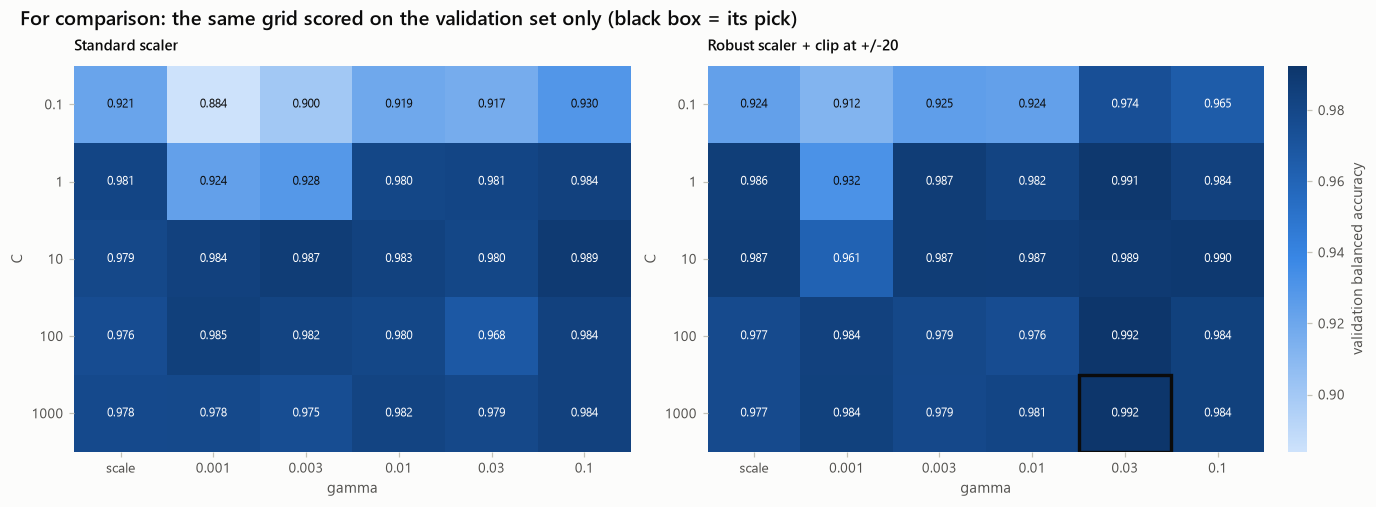

In [17]:
val_results, val_best = model.tune_on_validation(X_tr, y_tr, X_val, y_val)
row = cv_results[(cv_results.scaler == val_best["scaler"]) & (cv_results.C == val_best["C"])
                 & (cv_results.gamma_label == str(val_best["gamma"]))].iloc[0]
print("Validation-only pick:", val_best)
print(f"  validation balanced accuracy : {val_results.iloc[0]['val_bal_acc']:.4f}")
print(f"  cross-validated on train     : {row['cv_bal_acc']:.4f}  (chosen setting: {cv_results.iloc[0]['cv_bal_acc']:.4f})")
show(plots.plot_grid_heatmaps(val_results, val_best, value="val_bal_acc", value_label="validation balanced accuracy",
                              title="For comparison: the same grid scored on the validation set only (black box = its pick)"),
     "12_validation_only_grid")

The validation-only favourite scores lower in cross-validation than the chosen setting: one small validation set is a
noisy guide. So the settings come from cross-validation, and the validation set is used as an **independent check**
below.

## 5. Check the chosen model on the validation set

In [18]:
selection_model = model.build_model(**best).fit(X_tr, y_tr)
_, _, m_train = evaluate.evaluate(selection_model, train)
val_pred, val_score, m_val = evaluate.evaluate(selection_model, val)
display(pd.DataFrame({"Train": m_train, "Validation": m_val}).T)
display(evaluate.confusion(y_val, val_pred))

,accuracy,balanced_accuracy,unstable_recall,unstable_precision,unstable_f1,stable_recall,roc_auc,average_precision
Train,0.9766,0.9817,0.9896,0.8935,0.9391,0.9738,0.9982,0.9918
Validation,0.9698,0.9613,0.9479,0.8922,0.9192,0.9747,0.9943,0.9788


,predicted Unstable,predicted Stable
actual Unstable,91,5
actual Stable,11,423


In [19]:
display(evaluate.misclassified(val, val_pred, val_score))

,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,actual,predicted,instability_score
159,LT_00160,-4%,Line_Trip,LineTrip_3_4_Ckt1_Fault0p5s,Stable,Unstable,0.412
167,LT_00168,-4%,Line_Trip,LineTrip_4_14_Ckt1_Fault0p3s,Stable,Unstable,0.237
269,LT_00270,-2%,Line_Trip,LineTrip_4_14_Ckt1_Fault0p3s,Stable,Unstable,0.695
814,GF_00815,-4%,Ground_Fault_Line_Trip,LLG_Line5_6_Ckt1_Loc80pct_Fault0p5s,Stable,Unstable,0.081
1025,GF_01026,-4%,Ground_Fault_Line_Trip,3PHG_Line16_17_Ckt1_Loc20pct_Fault0p3s,Stable,Unstable,0.836
1038,GF_01039,-4%,Ground_Fault_Line_Trip,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p1s,Unstable,Stable,-0.870
1637,GF_01638,-2%,Ground_Fault_Line_Trip,3PHG_Line16_17_Ckt1_Loc20pct_Fault0p3s,Stable,Unstable,1.044
1650,GF_01651,-2%,Ground_Fault_Line_Trip,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p1s,Unstable,Stable,-0.881
2105,GF_02106,0%,Ground_Fault_Line_Trip,3PHG_Line7_8_Ckt1_Loc20pct_Fault0p3s,Stable,Unstable,0.322
2249,GF_02250,0%,Ground_Fault_Line_Trip,3PHG_Line16_17_Ckt1_Loc20pct_Fault0p3s,Stable,Unstable,1.329


Errors cluster in a few contingencies: a contingency that is hard for the model is usually hard at several load
levels. Rare contingency kinds are a weak spot - there are only 10 generator-trip contingencies in the whole dataset
(per-set counts in section 3).

,fraction,training_rows,train_bal_acc,val_bal_acc
0,0.1,265,0.9854,0.9196
1,0.2,530,0.9751,0.8728
2,0.4,1060,0.9802,0.9028
3,0.6,1595,0.9843,0.9717
4,0.8,2125,0.9839,0.9601
5,1.0,2655,0.9817,0.9613


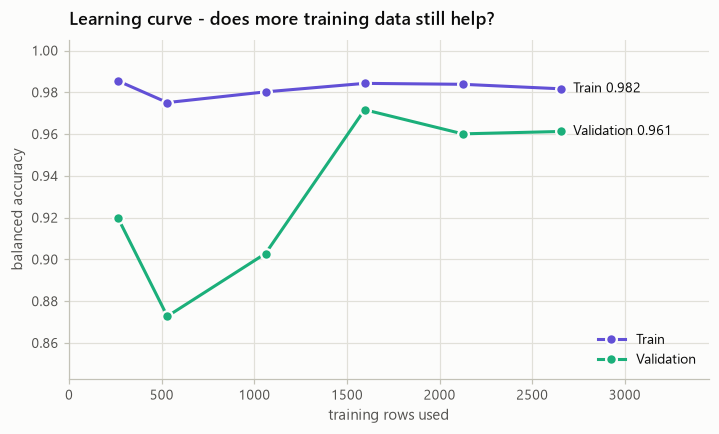

In [20]:
lc = evaluate.learning_curve_on_validation(train, val, best)
display(lc)
show(plots.plot_learning_curve(lc), "13_learning_curve")

A validation curve that is still rising at the right-hand end means more data of the same kind would help; a flat
curve means the remaining errors come from specific contingencies unlike those in training, which more *diverse*
scenarios (e.g. more generator trips) would address.

## 6. Final model and test set

The chosen settings are refitted on **train + validation** (more data), and the final model is evaluated **once**
on the untouched test set.

Cross-validation on train: balanced accuracy 0.9743 +/- 0.0159
Train / Validation rows: model fitted on train.  Test row: final model (train + validation).


,accuracy,balanced_accuracy,unstable_recall,unstable_precision,unstable_f1,stable_recall,roc_auc,average_precision
Train,0.9766,0.9817,0.9896,0.8935,0.9391,0.9738,0.9982,0.9918
Validation,0.9698,0.9613,0.9479,0.8922,0.9192,0.9747,0.9943,0.9788
Test,0.9528,0.9551,0.9588,0.8158,0.8815,0.9515,0.9919,0.9644


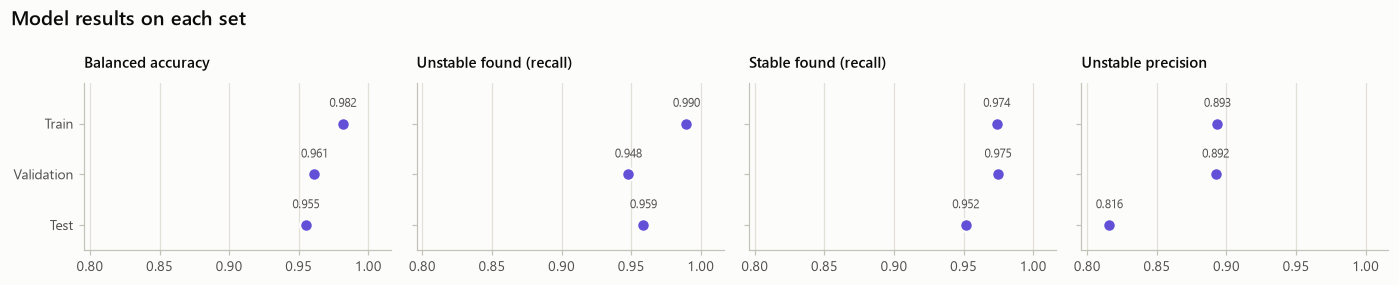

In [21]:
trainval = pd.concat([train, val])
final = model.build_model(**best).fit(*data.get_xy(trainval))
test_pred, test_score, m_test = evaluate.evaluate(final, test)

results = pd.DataFrame({"Train": m_train, "Validation": m_val, "Test": m_test}).T
print(f"Cross-validation on train: balanced accuracy {cv_results.iloc[0]['cv_bal_acc']:.4f} "
      f"+/- {cv_results.iloc[0]['cv_std']:.4f}")
print("Train / Validation rows: model fitted on train.  Test row: final model (train + validation).")
display(results)
show(plots.plot_metric_dots(results), "14_metrics_by_set")

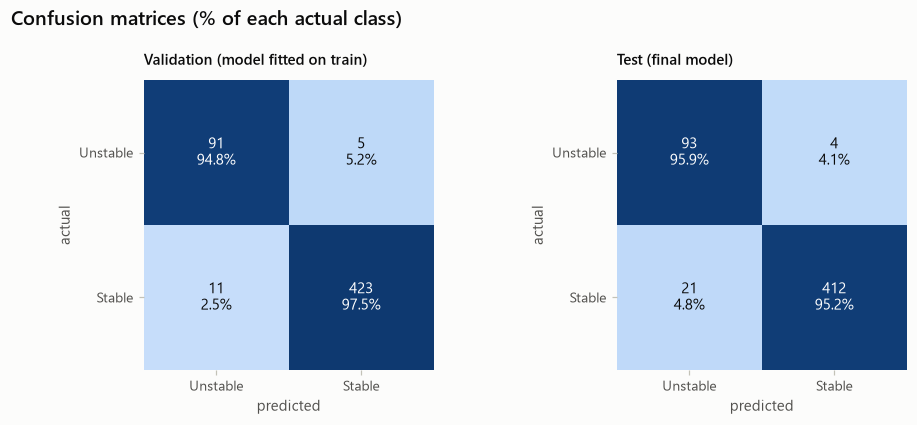

In [22]:
show(plots.plot_confusion_matrices({
    "Validation (model fitted on train)": evaluate.confusion(y_val, val_pred),
    "Test (final model)": evaluate.confusion(y_te, test_pred)}), "15_confusion_matrices")

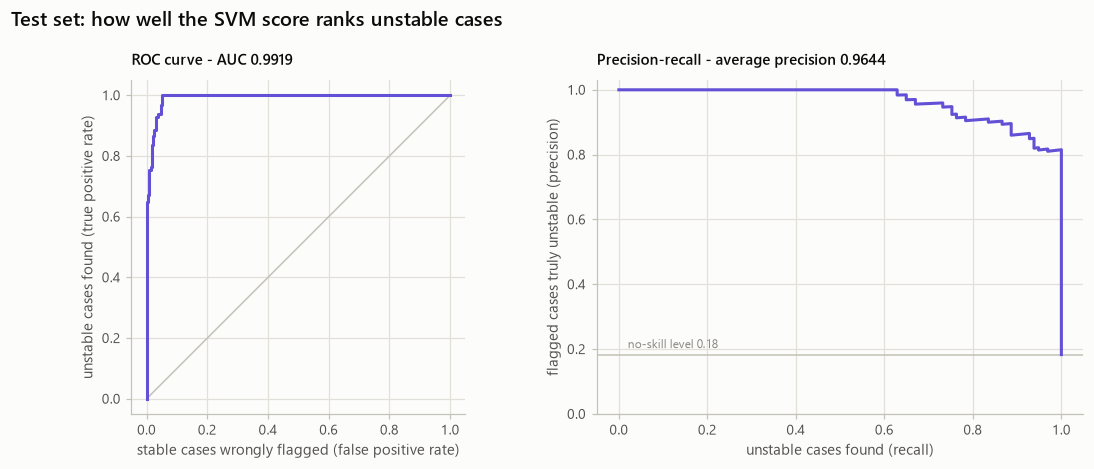

In [23]:
show(plots.plot_roc_pr(y_te, test_score), "16_roc_pr_test")

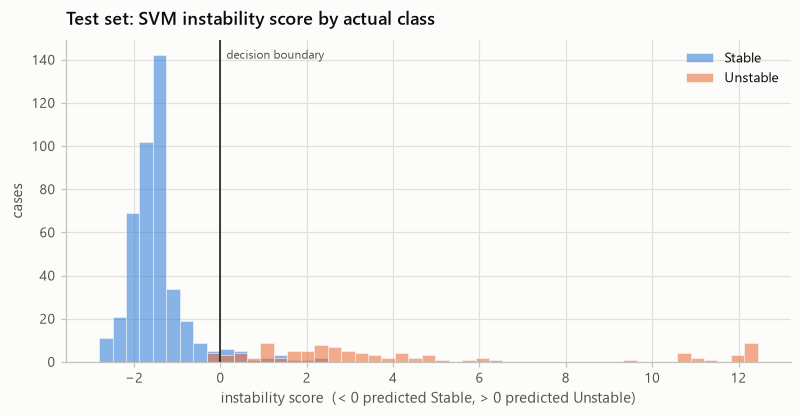

In [24]:
show(plots.plot_score_distribution(y_te, test_score), "17_score_distribution_test")

The **instability score** is the SVM's signed distance from its decision boundary (> 0 → unstable). Cases far from 0
are clear-cut; the errors sit close to the boundary.

,cases,accuracy,unstable,unstable_found,unstable_missed,false_alarms
Contingency_Type,,,,,,
Generator_Trip,5,0.0000,0,0,0,5
Ground_Fault_Line_Trip,435,0.9724,64,60,4,8
Line_Trip,80,0.9000,33,33,0,8
Load_Disconnection,10,1.0000,0,0,0,0


,cases,accuracy,unstable,unstable_found,unstable_missed,false_alarms
Load_Change_pct,,,,,,
-4.0,106,0.9434,14,13,1,5
-2.0,106,0.9528,17,16,1,4
0.0,106,0.9717,21,20,1,2
2.0,106,0.9434,22,21,1,5
4.0,106,0.9528,23,23,0,5


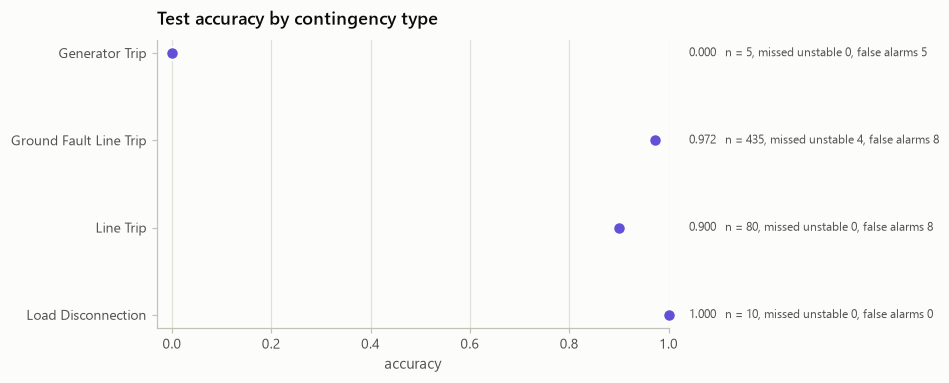

In [25]:
by_type = evaluate.breakdown(test, test_pred, "Contingency_Type")
display(by_type)
display(evaluate.breakdown(test, test_pred, "Load_Change_pct"))
show(plots.plot_breakdown_dots(by_type, "Test accuracy by contingency type"), "18_test_by_contingency_type")

In [26]:
display(evaluate.misclassified(test, test_pred, test_score))

,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,actual,predicted,instability_score
8,GT_00009,-4%,Generator_Trip,GenTrip_Bus38,Stable,Unstable,0.331
18,GT_00019,-2%,Generator_Trip,GenTrip_Bus38,Stable,Unstable,0.543
28,GT_00029,0%,Generator_Trip,GenTrip_Bus38,Stable,Unstable,0.813
38,GT_00039,+2%,Generator_Trip,GenTrip_Bus38,Stable,Unstable,1.128
48,GT_00049,+4%,Generator_Trip,GenTrip_Bus38,Stable,Unstable,1.506
219,LT_00220,-4%,Line_Trip,LineTrip_17_18_Ckt1_Fault0p5s,Stable,Unstable,0.426
227,LT_00228,-4%,Line_Trip,LineTrip_22_23_Ckt1_Fault0p3s,Stable,Unstable,1.339
230,LT_00231,-4%,Line_Trip,LineTrip_23_24_Ckt1_Fault0p3s,Stable,Unstable,2.194
329,LT_00330,-2%,Line_Trip,LineTrip_22_23_Ckt1_Fault0p3s,Stable,Unstable,1.532
431,LT_00432,0%,Line_Trip,LineTrip_22_23_Ckt1_Fault0p3s,Stable,Unstable,1.758


## 7. Which measurements does the model rely on?

**Permutation importance:** the 4 voltage (or frequency) samples of one bus are shuffled across the test cases and
the drop in balanced accuracy is measured (10 repeats). A big drop means the model depends on that measurement.

,bus,quantity,feature_group,importance,std
0,B31,voltage,B31 voltage,0.1208,0.0109
1,B34,frequency,B34 frequency,0.1193,0.0152
2,B38,voltage,B38 voltage,0.0498,0.0023
3,B31,frequency,B31 frequency,0.0319,0.0060
4,B35,voltage,B35 voltage,0.0212,0.0079
5,B32,frequency,B32 frequency,0.0206,0.0048
6,B36,voltage,B36 voltage,0.0205,0.0083
7,B33,frequency,B33 frequency,0.0161,0.0090
8,B39,frequency,B39 frequency,0.0152,0.0054
9,B32,voltage,B32 voltage,0.0151,0.0079


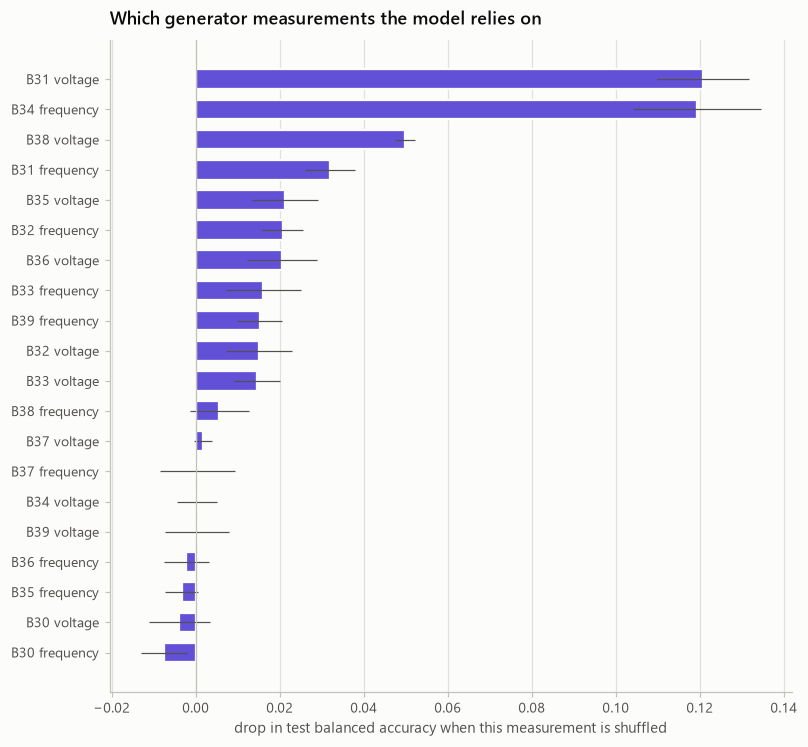

In [27]:
imp = evaluate.grouped_permutation_importance(final, test)
display(imp.head(10))
show(plots.plot_importance(imp), "19_feature_importance")

## 8. Save the model and predict new cases

`predict_case(vmag, freq)` takes two 10 x 4 tables - rows B30...B39, columns samples 1-4 - and returns the prediction.
The same is available from the command line: `python predict.py examples/example_case_unstable.csv`.

In [28]:
m_cv = {"balanced_accuracy": float(cv_results.iloc[0]["cv_bal_acc"]), "std": float(cv_results.iloc[0]["cv_std"])}
path = model.save_model(final, best, {"cv": m_cv, "train": m_train, "validation": m_val, "test": m_test}, trainval,
                        notes="First try: all rows kept, outliers not removed. Fitted on train + validation.")
print("Saved model to", path)

Saved model to E:\Data Anltics\models\stability_svm.joblib


In [29]:
from stability_svm.predict import predict_case
from stability_svm.config import BUSES

case = test.iloc[0]                                   # a test case the final model has never seen
vmag = [[case[f"{b}_Vmag_{k}"] for k in range(1, 5)] for b in BUSES]
freq = [[case[f"{b}_FreqHz_{k}"] for k in range(1, 5)] for b in BUSES]
print(pd.DataFrame(np.hstack([vmag, freq]), index=BUSES,
                   columns=[f"V{k}" for k in range(1, 5)] + [f"F{k}" for k in range(1, 5)]).round(4))
print("\nactual   :", "Stable" if case[LABEL] == STABLE else "Unstable", f"({case['Contingency_ID']}, {case['Operating_Condition']})")
print("predicted:", predict_case(vmag, freq))

         V1      V2      V3      V4       F1       F2       F3       F4
B30  0.9989  0.9967  0.9954  0.9946  49.9804  49.9279  49.8943  49.8708
B31  0.8065  0.8049  0.8035  0.8021  49.9942  49.9833  49.9770  49.9713
B32  0.9799  0.9786  0.9775  0.9764  49.9948  49.9838  49.9767  49.9699
B33  0.9978  0.9969  0.9959  0.9949  49.9861  49.9742  49.9686  49.9629
B34  1.0066  1.0045  1.0029  1.0015  49.9853  49.9696  49.9662  49.9641
B35  1.0173  1.0159  1.0147  1.0135  49.9948  49.9840  49.9770  49.9704
B36  1.0207  1.0196  1.0186  1.0177  49.9973  49.9879  49.9804  49.9727
B37  1.0158  1.0136  1.0118  1.0104  49.9830  49.9469  49.9244  49.9051
B38  0.8880  0.8860  0.8844  0.8830  49.9856  49.9558  49.9390  49.9261
B39  1.0197  1.0196  1.0195  1.0194  49.9990  49.9967  49.9951  49.9935

actual   : Stable (GenTrip_Bus38, -4%)
predicted: {'prediction': 'Unstable', 'instability_score': 0.3308, 'outside_training_range': ['B38_FreqHz_1', 'B38_FreqHz_2', 'B38_FreqHz_3', 'B38_FreqHz_4']}


This first test case happens to be one of the model's errors: the trip of the generator at **Bus 38**. The tool
reports that the B38 frequency samples lie **outside the range seen in training** - after this trip the B38 frequency
falls below every training case - so the model is extrapolating. Checking `outside_training_range` is therefore a
useful warning sign when the tool is used on new cases.

## 9. Summary

In [30]:
cv_best = cv_results.iloc[0]
print(f"Settings chosen by grouped 5-fold CV on train : {best}")
print(f"  cross-validated balanced accuracy           : {cv_best['cv_bal_acc']:.3f} +/- {cv_best['cv_std']:.3f}")
for name in ("Validation", "Test"):
    r = results.loc[name]
    print(f"{name:<10} balanced accuracy {r['balanced_accuracy']:.3f} | unstable caught {r['unstable_recall']:.1%} "
          f"| stable correct {r['stable_recall']:.1%} | ROC-AUC {r['roc_auc']:.3f}")

Settings chosen by grouped 5-fold CV on train : {'scaler': 'robust_clip', 'C': 10.0, 'gamma': 0.001}
  cross-validated balanced accuracy           : 0.974 +/- 0.016
Validation balanced accuracy 0.961 | unstable caught 94.8% | stable correct 97.5% | ROC-AUC 0.994
Test       balanced accuracy 0.955 | unstable caught 95.9% | stable correct 95.2% | ROC-AUC 0.992


**Reading the numbers.** Validation and test each hold ~106 contingencies, so their scores move by a few points
depending on which contingencies land in them - the cross-validation mean ± spread is the steadier estimate.

**Ideas for the next try**
1. **Handle the impossible readings** - remove, cap, or rely on the robust scaler, and compare with this first try.
2. **More generator-trip cases** - only 10 generator-trip contingencies exist; that is where the model is weakest.
3. **Decision threshold** - shifting the boundary of the instability score trades false alarms for fewer missed unstable cases.
4. **Extra features** - e.g. the spread of frequency between generators (alone it separates the classes very well).
5. **Compare other classifiers** (e.g. gradient boosting) against the SVM on the same split.